In [1]:
import pandas as pd
from pymodulon.core import IcaData
import numpy as np
from pymodulon import example_data
import cobra
import pickle
import sys
import matplotlib.pyplot as plt
import pickle
sys.path.append('../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
cobra.Configuration().solver = 'glpk'

In [3]:
with open('../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data4 = pickle.load(pickle_file)
    all_total_nutrient_count4 = data4['all_total_nutrient_count']
    all_total_intake4 = data4['all_total_intake']
    all_growth_rate4 = data4['all_growth_rate']
    all_random_medium4 = data4['all_random_medium']
    all_met_flux4 = data4['all_met_flux']
    del data4

In [4]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

Ecoli = cobra.io.load_json_model('../../Expression_datasets/palsson_nc/iML1515.json')

In [5]:
Ecoli_gpr = []
for rec in Ecoli.reactions:

    seedrec = rec.annotation.get('seed.reaction')
    if seedrec is None:
        continue

    seedrec = seedrec[0]

    if len(rec.genes) > 0:
        gene_id = [gene.id for gene in list(rec.genes) if gene.id not in ['Unknown']]
        Ecoli_gpr.append((seedrec, gene_id))
Ecoli_gpr = pd.DataFrame(Ecoli_gpr, columns=['Model_Reaction_ID', 'Gene_IDs'])
node_to_b = {}


for idx, group in cluster_nodes.items():
    for rec in group:
        try:
            genes = [a.id for a in Ecoli.reactions.get_by_id(rec[:-4]).genes]
        except:
            genes = None
        if genes is None:
            continue
        if idx not in node_to_b:
            node_to_b[idx] = []
        for gene in genes:
                node_to_b[idx].append(gene)

In [6]:
M = example_data.M
A = example_data.A
X = example_data.X 

ica = IcaData(M, A)
ica.X = X        

gene_table = example_data.gene_table
thresholds = pd.read_csv('../../Expression_datasets/palsson_nc/e_coli_precise278_thresholds.csv')
classification = pd.read_csv('../../Expression_datasets/palsson_nc/e_coli_precise278_classification.csv')

In [7]:
def get_imodulon_members(ica, thresholds=None):
    rows = {}
    for im in ica.M.columns:
        w = ica.M[im]
        if thresholds is not None:
            thr = np.array(thresholds[thresholds['imodulon_name'] == im])[0][2]
        else:
            thr = ica.thresholds[im]
        keep = np.abs(w) >= thr
        rows[im] = [g for g in w.index[keep]]
    return rows

In [8]:
node_b_sets = [set(b_list) for b_list in node_to_b.values()]
all_node_b = set().union(*node_to_b.values())
filtered_imodulon_members = {im: [g for g in genes if g in all_node_b] for im, genes in get_imodulon_members(ica, thresholds).items()}

imodulon_b_sets = [set(gene_list) for gene_list in filtered_imodulon_members.values()]

filtered_results = []
for imodulon_idx, imodulon_set in enumerate(imodulon_b_sets):
    overlaps = [len(imodulon_set & node_set) / len(imodulon_set) if (imodulon_set and node_set) else 0 for node_set in node_b_sets]
    max_overlap = max(overlaps)
    if max_overlap > 0:
        best_node = overlaps.index(max_overlap)
        imodulon_name = list(filtered_imodulon_members.keys())[imodulon_idx]
        filtered_results.append((imodulon_name, best_node, max_overlap, len(imodulon_set)))

In [9]:
node_sets = {node_idx: set(b_list) for node_idx, b_list in node_to_b.items()}
node_cols = sorted(node_sets.keys())  # e.g., [0,1,...,19]

imod_sets = {name: set(genes) for name, genes in filtered_imodulon_members.items()}

rows = []
for im_name, im_set in imod_sets.items():
    row = {"iModulon_name": im_name}
    for node_idx in node_cols:
        inter = im_set & node_sets[node_idx]
        row[node_idx] = sorted(inter)
    rows.append(row)

df_intersects = pd.DataFrame(rows).set_index("iModulon_name").reindex(columns=node_cols)

df_counts = df_intersects.applymap(len)

df_str = df_intersects.applymap(lambda lst: ",".join(lst))

df_genename = df_intersects.applymap(lambda lst: [gene_table["gene_name"].to_dict().get(b, b) for b in lst])

df_genename_str = df_genename.applymap(lambda lst: ",".join(lst))

In [10]:
def parse_cell(x):
    if pd.isna(x) or (isinstance(x, str) and x.strip() == ""):
        return []
    parts = [g.strip() for g in str(x).replace("，", ",").split(",")]
    return [g for g in parts if g]

df_list = df_genename_str.copy().applymap(parse_cell)

try:
    df_list.columns = [int(c) for c in df_list.columns]
except Exception:
    pass

def clean_scattered_in_row(row_lists: pd.Series, max_size: int = 2) -> pd.Series:
    lists = {col: (genes if isinstance(genes, list) else []) for col, genes in row_lists.items()}

    lens = {col: len(genes) for col, genes in lists.items()}
    max_len = max(lens.values()) if lens else 0
    if max_len <= 1:
        return pd.Series(lists, index=row_lists.index)

    max_cols = [col for col, L in lens.items() if L == max_len]
    max_gene_set = set()
    for col in max_cols:
        max_gene_set.update(lists[col])

    new_row = {}
    for col, genes in lists.items():
        if 0 < len(genes) <= max_size:
            kept = [g for g in genes if g not in max_gene_set]
            new_row[col] = kept
        else:
            new_row[col] = genes

    return pd.Series(new_row, index=row_lists.index)

df_list = df_list.apply(clean_scattered_in_row, axis=1)

long = df_list.stack().reset_index()
long.columns = ["iModulon", "node", "genes"]
long["gene_count"] = long["genes"].apply(len)

count_mat = long.pivot_table(index="iModulon", columns="node",
                             values="gene_count", fill_value=0, aggfunc="sum").sort_index(axis=1)

all_genes = set()
for lst in long["genes"]:
    all_genes.update(lst)

cdf = classification.copy()
if "imodulon_name" in cdf.columns:
    cdf["imodulon_name"] = cdf["imodulon_name"].astype(str).str.strip()

use_key = None
if "imodulon_k" in cdf.columns and pd.api.types.is_numeric_dtype(count_mat.index):
    use_key = "imodulon_k"
    idx_series = pd.Index(count_mat.index, name="imodulon_k")
else:
    use_key = "imodulon_name"
    idx_series = pd.Index(count_mat.index.astype(str).str.strip(), name="imodulon_name")

orig_classes = (
    cdf.drop_duplicates(subset=[use_key])[[use_key, "classification"]]
       .set_index(use_key)
       .reindex(idx_series)["classification"]
)

filtered_index = idx_series[count_mat.max(axis=1).values <= 1]
filt_classes = orig_classes.reindex(filtered_index)

orig_counts = orig_classes.value_counts(dropna=False)
filt_counts = filt_classes.value_counts(dropna=False)

all_cats = pd.Index(sorted(set(orig_counts.index) | set(filt_counts.index), key=lambda x: str(x)))
orig_counts = orig_counts.reindex(all_cats).fillna(0).astype(int)
filt_counts = filt_counts.reindex(all_cats).fillna(0).astype(int)


In [11]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests


imod_sets = {im: set(sum(df_list.loc[im].tolist(), [])) for im in df_list.index}
node_sets = {nd: set(sum(df_list[nd].tolist(), [])) for nd in df_list.columns}

def pairwise_overlap_stats(A, B):
    inter = len(A & B)
    a, b = len(A), len(B)
    jacc = inter / (a + b - inter) if (a + b - inter) > 0 else 0.0
    over = inter / min(a, b) if min(a, b) > 0 else 0.0  # Szymkiewicz–Simpson
    prec = inter / b if b > 0 else 0.0
    reca = inter / a if a > 0 else 0.0
    f1 = (2*prec*reca)/(prec+reca) if (prec+reca)>0 else 0.0
    return inter, jacc, over, f1

rows, cols, inters, jaccs, overs, f1s = [], [], [], [], [], []
for im, A in imod_sets.items():
    for nd, B in node_sets.items():
        inter, jacc, over, f1 = pairwise_overlap_stats(A, B)
        rows.append(im); cols.append(nd)
        inters.append(inter); jaccs.append(jacc); overs.append(over); f1s.append(f1)

sim_df = pd.DataFrame({
    "iModulon": rows, "node": cols,
    "intersection": inters,
    "jaccard": jaccs, "overlap": overs, "f1": f1s
})

U = len(all_genes)
fisher_rows = []
for im, A in imod_sets.items():
    a = len(A)
    for nd, B in node_sets.items():
        b = len(B)
        inter = len(A & B)
        table = [[inter, b - inter],
                 [a - inter, U - a - b + inter]]
        if any(x < 0 for row in table for x in row):
            p = 1.0
        else:
            _, p = fisher_exact(table, alternative="greater")
        fisher_rows.append((im, nd, inter, a, b, p))

fisher_df = pd.DataFrame(fisher_rows, columns=["iModulon","node","intersection","|A|","|B|","p"])
fisher_df["p_adj"] = multipletests(fisher_df["p"].values, method="fdr_bh")[1]
fisher_sig = fisher_df.sort_values(["p_adj","intersection"], ascending=[True, False])

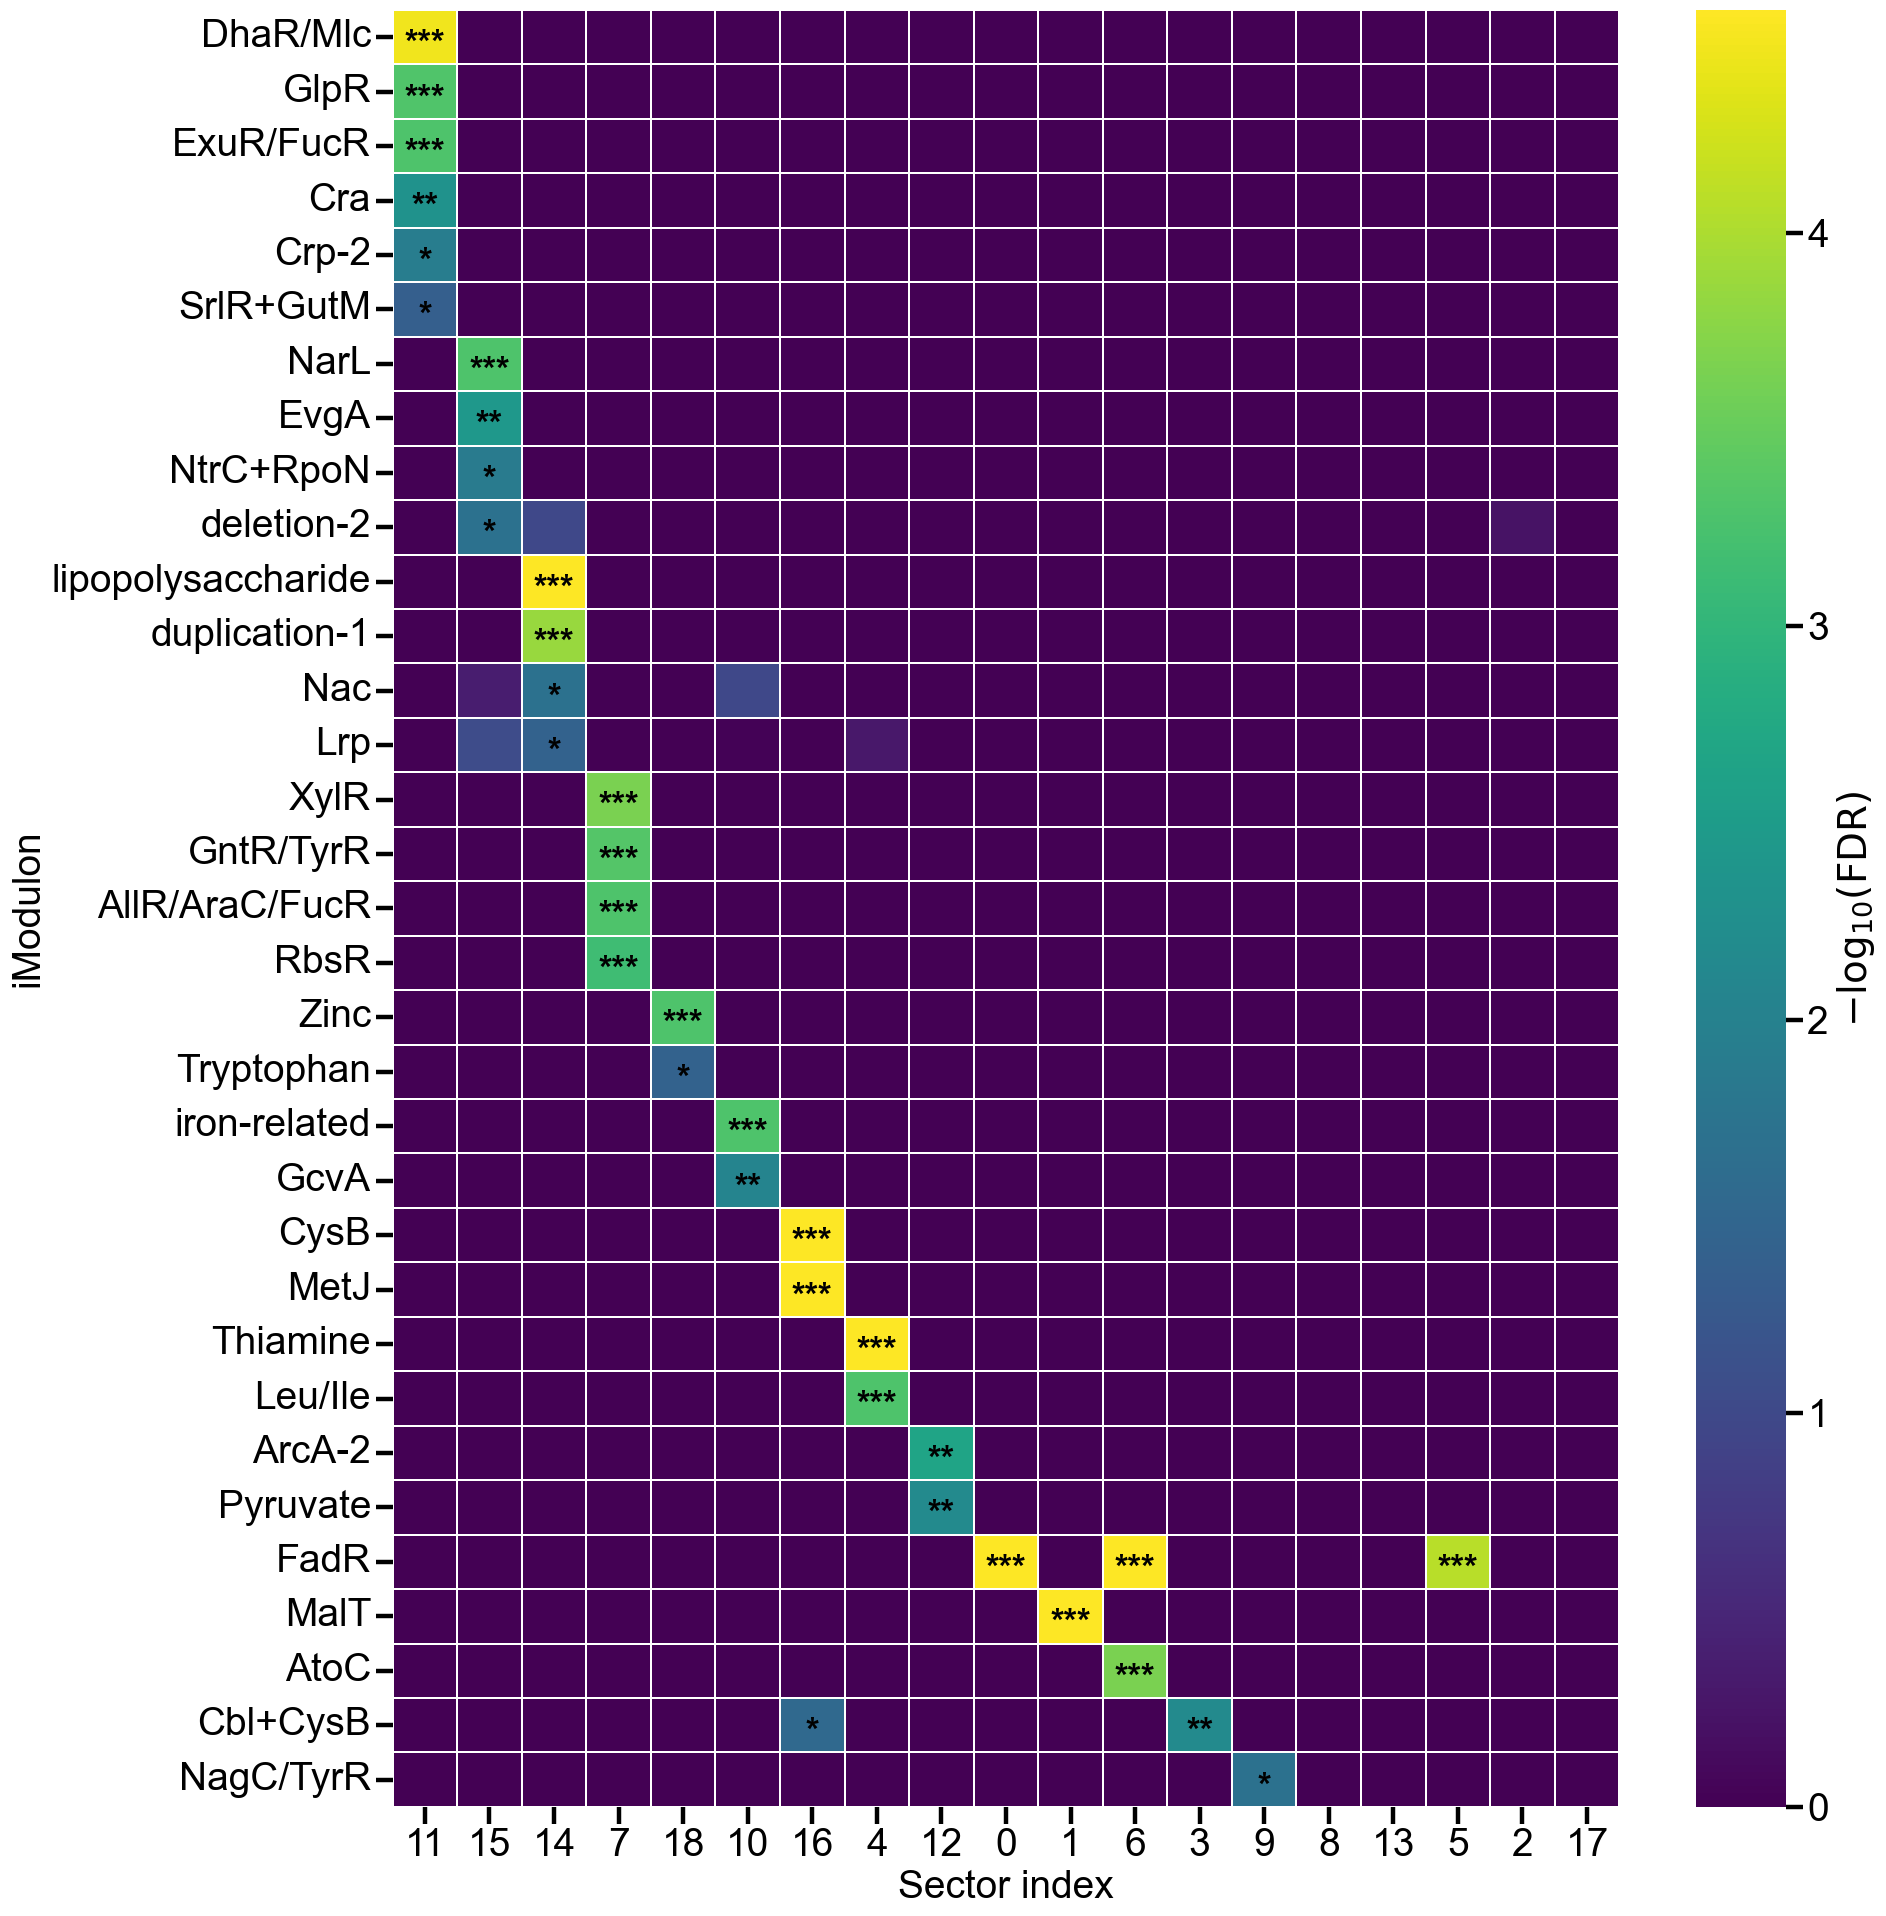

In [ ]:
set_panel_style(scale=4)
padj_mat = fisher_df.pivot(index="iModulon", columns="node", values="p_adj") 
logp = -np.log10(padj_mat.replace(0, np.nextafter(0, 1))).fillna(0)

thr = 1.3
mask_keep = (logp.max(axis=1) >= thr)
logp_f = logp.loc[mask_keep]
row_argmax = logp_f.idxmax(axis=1) 
col_freq = row_argmax.value_counts().reindex(logp_f.columns, fill_value=0) 
col_order = col_freq.sort_values(ascending=False).index.tolist()
col_rank = {c: i for i, c in enumerate(col_order)} 
row_order = (pd.DataFrame({"am": row_argmax, "maxv": logp_f.max(axis=1)}).assign(rank=lambda d: d["am"].map(col_rank)) .sort_values(["rank", "maxv"], ascending=[True, False]).index ) 
M = logp_f.loc[row_order, col_order]

fig, ax = plt.subplots(figsize=(20, max(5, 0.6 * M.shape[0])))

cmap = "viridis"

vmax = max(thr, float(np.nanpercentile(M.values, 99)))

sns.heatmap(
    M,
    ax=ax,
    cmap=cmap,
    vmin=0,
    vmax=vmax,
    linewidths=0.2,
    linecolor="#FFFFFF",
    cbar_kws={"label": r"$-\log_{10}(\mathrm{FDR})$"},
    annot=False
)

vals = M.values

coords = np.argwhere(vals >= 1.3)
for (i, j) in coords:
    v = vals[i, j]
    if v >= 3:
        s = "***"
    elif v >= 2:
        s = "**"
    else:  # 1.3 <= v < 2
        s = "*"

    ax.text(
        j + 0.5, i + 0.65, s,
        ha="center", va="center",
        color="black",
        fontsize=25, fontweight="bold",
        zorder=10,
        clip_on=False
    )

ax.set_xticks(np.arange(M.shape[1]) + 0.5)
ax.set_xticklabels(M.columns.tolist(), rotation=0)

ax.set_xlabel("Sector index")
ax.set_ylabel("iModulon")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

[filter] kept 20 / 52 iModulons (tau_frac=0.7)


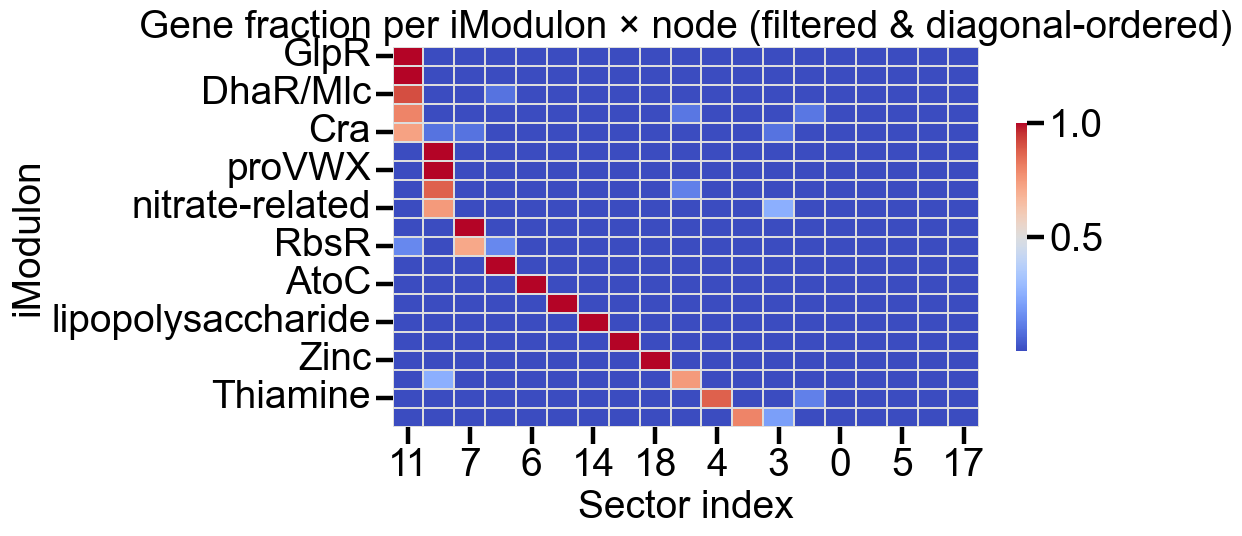

In [ ]:
filtered_count_mat = count_mat.loc[~count_mat.index.isin(filtered_index)]
frac = filtered_count_mat.div(filtered_count_mat.sum(axis=1), axis=0).fillna(0)

tau_frac = 0.7
keep = (frac.max(axis=1) >= tau_frac)
frac_f = frac.loc[keep]
print(f"[filter] kept {keep.sum()} / {len(keep)} iModulons (tau_frac={tau_frac})")
if frac_f.shape[0] == 0:
    raise ValueError("All rows filtered; lower tau_frac or check data.")

row_argmax = frac_f.idxmax(axis=1)
row_maxval = frac_f.max(axis=1)

col_hits = row_argmax.value_counts().reindex(frac_f.columns, fill_value=0)
col_sum  = frac_f.sum(axis=0)
col_order = (pd.DataFrame({"hits": col_hits, "sum": col_sum})
             .sort_values(["hits","sum"], ascending=[False, False]).index.tolist())

col_rank = {c:i for i,c in enumerate(col_order)}
row_order = (pd.DataFrame({"am": row_argmax, "maxv": row_maxval})
             .assign(rank=lambda d: d["am"].map(col_rank))
             .sort_values(["rank","maxv"], ascending=[True, False]).index)

M = frac_f.loc[row_order, col_order]

vals = M.values
pos = vals[vals>0]
vmax = np.percentile(pos, 99) if pos.size else 1.0
vmin = 1e-6
cmap = plt.cm.coolwarm.copy()

plt.figure(figsize=(12, max(5, 0.3*M.shape[0])))
ax = sns.heatmap(M, cmap=cmap, vmin=vmin, vmax=vmax,
                 linewidths=0.3, linecolor="#ddd",
                 cbar=True, cbar_kws={"shrink":0.6})
ax.set_title("Gene fraction per iModulon × node (filtered & diagonal-ordered)")
ax.set_xlabel("Sector index"); ax.set_ylabel("iModulon")
ax.set_ylim(M.shape[0], 0) 
plt.tight_layout()
plt.show()
